# Preparing an Arbitrary State with Alias Sampling
$$
\renewcommand{\ket}[1]{|#1\rangle}
\renewcommand{\bra}[1]{\langle#1|}
$$

The first arbitrary state preparation tutorial presents how to use a cascading sequence of multiplexed rotations to prepare a quantum state. In this follow-up tutorial, we present an additional method that is a coherent version of a classical sampling method. 

In Workbench Algorithms, this is implemented via the [`AliasSampling`](https://docs.construct.psiquantum.com/psiqdk-algorithms/autoapi/psiqdk/algorithms/state_preparation/index.html#psiqdk.algorithms.state_preparation.AliasSampling) Qubrick. 



In [1]:
from psiqdk.workbench import Qubits, QPU
from psiqdk.algorithms import (
    AliasSampling, 
    SelectNaive, 
    SwapUp, 
    DataLookupClean, 
    USP
)

## Alias sampling

The key idea behind alias sampling is to split a large sampling problem into a collection of equally-likely sub-problems, where each sub-problem only samples from two items. This results in a very efficient way to sample: we randomly select a pair and then pick one of the two items with a probability in correspondence with the original distribution. Similarly, the quantum alias sampling algorithm on $n$ qubits starts by preparing an equal superposition of $2^n$ basis states and then conditionally swaps each of them with a different one to achieve the required probability distributions of the basis state in the final superposition. For a deep dive, you can see this [blog post](https://algassert.com/post/1805) from Craig Gidney. 

Figure 11 of "Encoding Electronic Spectra in Quantum Circuits with Linear T Complexity" ([arXiv:1805.03662](https://arxiv.org/abs/1805.03662)) presents the coherent implementation of this algorithm. It is composed of a uniform state preparation, a data loader, a comparator and a controlled swap. 

The `AliasSampling` Qubrick is initialized with a data loading routine (`qrom`) and a uniform state preparation routine (`usp`). See the [QROM tutorial](Data_Loaders_QROM.ipynb) and the [USP tutorial](Uniform_State_Preparation.ipynb) to explore the routines which can be used as these arguments. 

The `compute` method takes the arguments: 
- the target register (`prep_reg`, type Qubits),
- the probabilities of the basis states defining the superposition state to prepare (`input_list`, type List(float)),
- the number of bits used to represent each probability (`bit_precision`, type int),
- an optional control qubit (`ctrl`, type Qubits),
- optional keyword arguments to be passed to the data loader subroutine, for example, the lambda value.

> Note that this algorithm is restricted to loading classical (real, positive) probability distributions.

The following example shows how to load a state with real positive coefficients using the `AliasSampling` Qubrick.

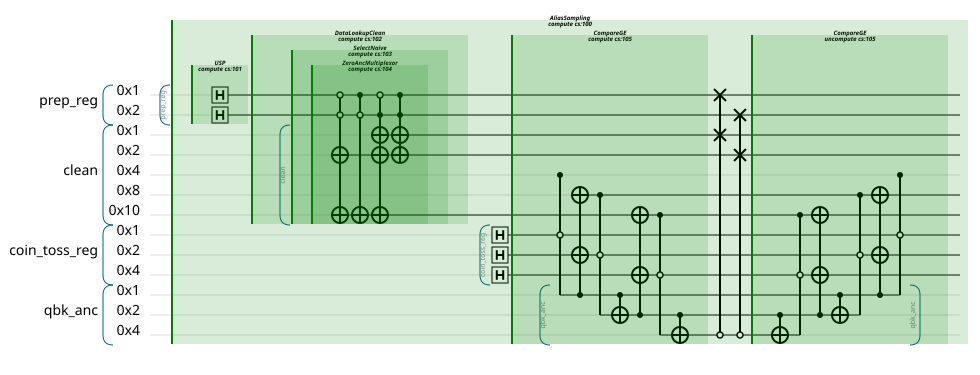

In [2]:
# Set up weights of desired state and choose a bit precision
desired_probs = [2 / 8, 1 / 8, 2 / 8, 3 / 8]
bits_of_precision = 3

qpu = QPU(num_qubits=13)
prep_reg = Qubits(2, 'prep_reg', qpu)

# Set up Qubricks
usp = USP()
select = SelectNaive()
swap_up = SwapUp()
qrom = DataLookupClean(select, swap_up)
alias_sampling_prep = AliasSampling(qrom=qrom, usp=usp)

# Call compute on AliasSampling Qubrick
alias_sampling_prep.compute(prep_reg, desired_probs, bits_of_precision, lambda_val=1)

qpu.draw(show_qubricks=True)

The sub-sampling process is equivalent to rolling a fair dice followed by flipping a biased coin. The less likely item in each pair is referred to as the "alias" and the bias value is referred to as the "threshold". Using this picture, we can interpret the steps in the circuit as:

1. Emulate a fair die over $2^n$ options 
    
    - We perform a uniform state preparation over the `prep_reg`.

2. Based on the value 'rolled', select two things: the alias state and the corresponding threshold value

    - Use a QROM to load the alias and threshold to `clean` indexed on `prep_reg`.

    - Under the hood, the relevant alias and corresponding threshold are calculated via the [`generate_alias_table`](https://docs.construct.psiquantum.com/psiqdk-algorithms/autoapi/psiqdk/algorithms/utils/alias_sampling_utils/index.html#psiqdk.algorithms.utils.alias_sampling_utils.generate_alias_table) function.
        
    - In this example, the alias states are [2, 0, 3, 3] and the threshold values are [4, 4, 4, 0].

    - We can see these values being written the the top two and bottom three qubits of `clean`, respectively, via the QROM.

4. Emulate a biased coin toss

    - We instantiate an equal superposition in the `coin_toss_reg` and compare the values in this register to the subregister of `clean` holding the threshold values. Both these registers use `bits_of_precision` qubits to emulate probabilities from $0$ to $1$ with this precision.
    - If the value in `coin_toss_reg` is greater than or equal to the threshold, we swap the current state of `prep_reg` with the subregister of `clean` holding the alias state.

Let's check that we have prepared the expected state by using `peek_read_probability`:

In [3]:
print(f'Desired probabilities =\n {desired_probs}')

probabilities = []
for i in range(len(desired_probs)):
    probabilities.append(round(prep_reg.peek_read_probability(i), 6))
print(f'Prepared probabilities =\n {probabilities}')

Desired probabilities =
 [0.25, 0.125, 0.25, 0.375]
Prepared probabilities =
 [0.25, 0.125, 0.25, 0.375]


Unlike the previous examples, this Qubrick does not immediately uncompute the auxiliary qubits `clean` and `coin_toss_reg`. These qubits remain entangled with the prepared register and they will need to persist until we call the `uncompute` method. We can see this by printing the full state vector:

In [4]:
qpu.print_state_vector();

|prep_reg|clean|coin_toss_reg|?>
|0|17|4|.>    0.176777+0.000000j
|0|17|5|.>    0.176777+0.000000j
|0|17|6|.>    0.176777+0.000000j
|0|17|7|.>    0.176777+0.000000j
|0|18|0|.>    0.176777+0.000000j
|0|18|1|.>    0.176777+0.000000j
|0|18|2|.>    0.176777+0.000000j
|0|18|3|.>    0.176777+0.000000j
|1|16|0|.>    0.176777+0.000000j
|1|16|1|.>    0.176777+0.000000j
|1|16|2|.>    0.176777+0.000000j
|1|16|3|.>    0.176777+0.000000j
|2|16|4|.>    0.176777+0.000000j
|2|16|5|.>    0.176777+0.000000j
|2|16|6|.>    0.176777+0.000000j
|2|16|7|.>    0.176777+0.000000j
|2|19|0|.>    0.176777+0.000000j
|2|19|1|.>    0.176777+0.000000j
|2|19|2|.>    0.176777+0.000000j
|2|19|3|.>    0.176777+0.000000j
|3|3|0|.>    0.176777+0.000000j
|3|3|1|.>    0.176777+0.000000j
|3|3|2|.>    0.176777+0.000000j
|3|3|3|.>    0.176777+0.000000j
|3|3|4|.>    0.176777+0.000000j
|3|3|5|.>    0.176777+0.000000j
|3|3|6|.>    0.176777+0.000000j
|3|3|7|.>    0.176777+0.000000j
|3|18|4|.>    0.176777+0.000000j
|3|18|5|.>    0.17

## Summary

In this tutorial, we walked through state preparation onto a QPU using coherent alias sampling.

$\text{AliasSampling}$ prepares a state with given real, positive probabilities of basis states.

This algorithm does not rely on expensive arbitrary rotations, which is one reason it may be preferred over multiplexed rotation based methods. However, it does so at the cost of auxiliary qubits. Moreover, these remain entangled with the main register meaning that we have to hang on to them until uncompute is called. 

Have fun preparing arbitrary states!